# 02d · Random Forest process emulator

Predict local **thickness and conductivity maps** from a process recipe and planned substrate XY.
Use a **Random Forest regressor per observed property**, with 300 trees, bounded tree depth, and a fixed seed. Each point is predicted from its recipe, physical X/Y, and local temperature, independently of the other queried points.

**Prediction unit:** one feature row per location (recipe + physical X/Y + local temperature),
yielding thickness and conductivity at that location. Ridge/KRR/MLP/Random Forest predict independently,
whether queried alone or in a batch. Save point predictions with their identity/XY first; only then
pivot them into a grid for visualization, without averaging, interpolation, or smoothing. The GNN
also predicts per location, but is explicitly neighbor-aware and requires the full planned grid.

**Fixed comparison contract:** run notebook 01 once, then all five algorithm notebooks without
rerunning data preparation. Reuse the same material-stratified whole-deposition/identical-recipe
splits, features, train-only transforms, two log targets, and eligible labels. No spectra, measured
composition/properties, IDs, or label-availability flags enter the inputs. Whole-grid identity stays
intact. Models save separate outputs; no algorithm can overwrite another's run.

**Shared chemistry inputs:** source-formula descriptors (electronegativity, atomic mass/size,
ionization energy, elemental fractions, and independent reference band-gap statistics) replace
source-name one-hot columns. Recipe source/power slots remain paired. Reference gaps are not
measured film properties or certified target-phase values; missing coverage is explicit.
Power-weighted descriptors are not inferred deposited-film stoichiometry. See notebook 01 for
references, coverage, and training-only imputation. No architecture adds its own features.

**Frozen instructor-selected features:** notebook 01 uses the offline specification selected by
an instructor-only grouped training/validation comparison. Candidate additions include curated
composition descriptors, published MEGNet composition vectors, real frozen ALIGNN reference-crystal
vectors and compact reference DOS. Only selected blocks enter the matrices. Reference crystals/DOS
are not verified source phases or measured film information. No architecture downloads an encoder,
selects features, fits PCA, or changes preprocessing. All five models read the same checksummed
matrices. Your experiment changes the ML algorithm/architecture, not the data preparation.

**Expanded observations:** a position needs at least one observed property, not both. Ridge/KRR/forests
fit each output on its observed labels; neural models use a per-property masked MSE with equal
property weighting. Missing labels remain NaN, never fabricated. Each node also has a local
temperature from the source `absolute_temp_c` profile. Inference requires a planned/calibrated
temperature map; missing temperature is explicitly imputed, not assumed equal to initial temperature.
Original split assignments are frozen; new groups are material-balanced around them. The summary
also reports the original paired test points separately for an honest before/after comparison.

Workshop cycle: **baseline → hypothesis → one model change → validation → final reporting**.
The default 02 stays linear Ridge regardless of which model ranks first in notebook 03.

In [1]:
from pathlib import Path
import sys, json
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
HERE = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [parent, parent / '03_htem_conductivity']:
        if (candidate / 'htem_experiments.py').exists():
            HERE = candidate
            break
    if HERE is not None: break
if HERE is None:
    raise FileNotFoundError('Open from the workshop, HTEM module, or its examples folder.')
sys.path.insert(0, str(HERE))
import htem_workshop as htem
import htem_experiments as exp
ctx = exp.load_context(HERE)  # Validate and reuse notebook 01; NEVER redo preparation/splitting.
print('Shared frozen feature set:', ctx.manifest['frozen_feature_selection']['candidate'])
SEED = ctx.manifest['seed']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

EXPERIMENT_ID = 'random_forest'
RESULTS = HERE / 'outputs/htem_architectures' / EXPERIMENT_ID
RESULTS.mkdir(parents=True, exist_ok=True)
X_train, y_train = ctx.data['train']['X'], ctx.data['train']['y']
X_val, y_val = ctx.data['validation']['X'], ctx.data['validation']['y']
print('Same prepared data:', ctx.fingerprint['prepared_manifest_sha256'][:12])
display(pd.DataFrame([{'split': s, 'labeled_points': len(ctx.data[s]['X']),
                       'depositions': len(np.unique(ctx.data[s]['library_id'])),
                       'thickness_labels': int(ctx.data[s]['y_mask'][:, 0].sum()),
                       'conductivity_labels': int(ctx.data[s]['y_mask'][:, 1].sum())} for s in htem.SPLITS]))
print(f'{X_train.shape[1]} encoded inputs → 2 standardized log targets.')

Shared frozen feature set: curated_crystal_dos
Same prepared data: 4cc9f6386925


,split,labeled_points,depositions,thickness_labels,conductivity_labels
0,train,22272,520,21360,6377
1,validation,7127,166,6776,2260
2,test,7363,173,7182,2289


361 encoded inputs → 2 standardized log targets.


## 1. Fit the model; use validation, never test, for choices

**Hypothesis prompt:** “Try tree ensembles to learn nonlinear process-by-position interactions. Keep the prepared data and grouped splits unchanged; expose tree count, maximum depth, minimum leaf size, and feature sampling. Compare validation error and spatial maps without tuning on test. Keep the supplied data contract unchanged. Explain each change,
preserve reproducibility, and compare validation error before final test reporting.”

In [2]:
from sklearn.ensemble import RandomForestRegressor
configuration = {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 3,
                 'max_features': 0.7, 'bootstrap': True, 'oob_score': False,
                 'random_state': SEED, 'n_jobs': 4}
print('Fitting one Random Forest per property on its observed training labels...')
started = perf_counter()
model = exp.fit_observed_regressors(RandomForestRegressor(**configuration), X_train, y_train)
fit_seconds = perf_counter() - started
history = trials = None
training_note = {'selection': 'one fixed configuration; validation reporting only; no test tuning',
                 'training': 'separate forests on observed labels; no epochs or early stopping'}
print(f'Fitted {len(model.estimators_)} forests in {fit_seconds:.1f} seconds.')

Fitting one Random Forest per property on its observed training labels...


Fitted 2 forests in 110.0 seconds.


Random Forest averages bootstrapped decision trees and can learn nonlinear recipe-by-position
interactions. Tree predictions are piecewise rather than inherently smooth gradients; improvement
is not guaranteed. The same StandardScaler/log-target transforms are retained for a fair comparison,
although trees do not require scaled inputs. Each property uses only its observed training labels.
There are no neural epochs, learning rate, or early-stopping loss curves. This is one fixed
configuration, not a hyperparameter search. Use the grouped validation set for subsequent changes;
ordinary row-level out-of-bag scores would not be a whole-deposition holdout.
See [scikit-learn RandomForestRegressor](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

## Evaluate the same train, validation, and test points

**Analysis prompt:** “Report each property's error and the training/validation gap. Invert the
existing transforms, preserve library/position/XY, and show parity plots for all three splits.
Do not tune using test results. Be honest about weak conductivity predictions.”

Conductivity log error is in decades: 1 decade means a factor of 10. Raw conductivity metrics are
also saved, but extreme values dominate them. These observational models are not causal simulators.

Validation score (mean standardized RMSE): 0.6576
Standardized target MSE: {'train': 0.0323, 'validation': 0.4464, 'test': 0.7918}


,split,target,MAE,MSE,RMSE,R2,n
0,train,thickness_um,0.0230,0.0075,0.0864,0.9659,21360
2,train,log10_conductivity,0.1997,0.1677,0.4095,0.9585,6377
3,validation,thickness_um,0.1240,0.0442,0.2102,0.7356,6776
5,validation,log10_conductivity,1.1573,2.4290,1.5585,0.4323,2260
6,test,thickness_um,0.1816,0.1078,0.3284,0.4548,7182
8,test,log10_conductivity,1.3626,3.8583,1.9642,0.2115,2289


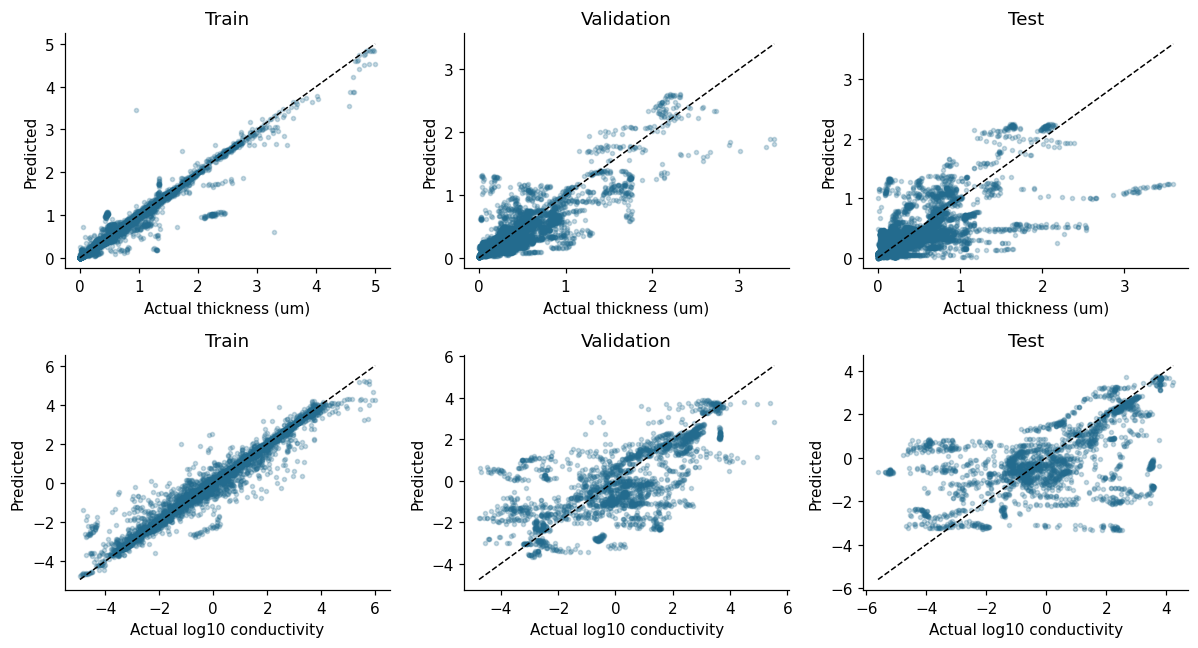

In [3]:
RESULTS, metrics, run = exp.evaluate_and_save(
    ctx, model, EXPERIMENT_ID, configuration, fit_seconds,
    history=history, training_note=training_note, trials=trials)
print(f"Validation score (mean standardized RMSE): {run['validation_score']:.4f}")
print('Standardized target MSE:', {s: round(v, 4) for s, v in run['standardized_MSE'].items()})
display(metrics[metrics.target.ne('conductivity_S_cm')].round(4))
predictions = pd.read_csv(RESULTS / 'predictions.csv', dtype={'sample_id': str})
fig = exp.plot_parity(predictions)
fig.savefig(RESULTS / 'parity_all_splits.png', bbox_inches='tight')
plt.show()

## Compare maps for the same held-out deposition

All algorithm notebooks select the same test library by eligible point count, not favorable error.
Predict its **full planned grid**; missing measured labels remain blank. No interpolation, fixed-size
reshape, or averaging across positions/depositions is allowed. Color limits match actual/predicted.

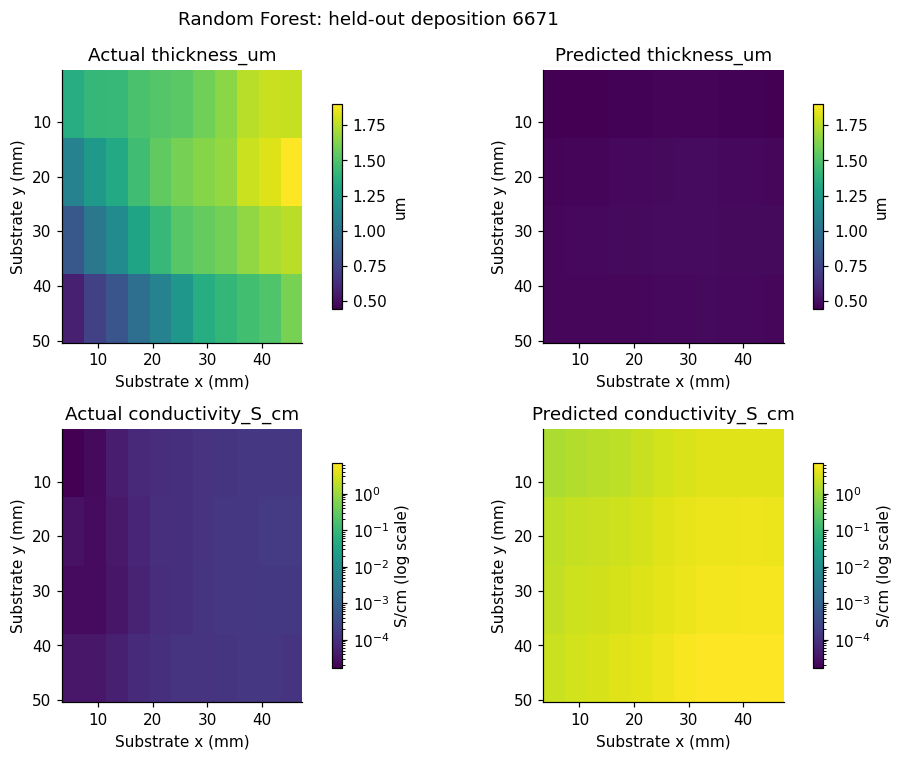

In [4]:
full_map = pd.read_csv(RESULTS / 'heldout_map.csv')
MAP_LIBRARY_ID = int(run['map_library_id'])
fig = htem.plot_substrate_maps(full_map, MAP_LIBRARY_ID)
fig.suptitle(f"{run['name']}: held-out deposition {MAP_LIBRARY_ID}")
fig.tight_layout()
fig.savefig(RESULTS / 'heldout_maps.png', bbox_inches='tight')
plt.show()

## Predict a recipe on a requested grid using the saved model

Edit `recipe` below, or supply planned `position/x_mm/y_mm` coordinates in the HTEM substrate frame.
Do not pass measured outputs or stage/focus `xyz_mm`. Use a **full planned grid** for graph inference;
changing nodes changes neighborhoods. For grids missing entire coordinate levels, specify known
`spacing_mm=(dx, dy)` rather than guessing nominal spacing. Load only trusted local joblib artifacts.

C:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code\03_htem_conductivity\htem_experiments.py:239: UserWarning: Optional recipe settings missing: using training-only imputation.
  warnings.warn("Optional recipe settings missing: using training-only imputation.")


C:\Users\mjym8d\OneDrive - University of Missouri\MigratedBoxFiles\Conferences\2026-11_AVS\Workshop_Matthias_Derek_Matt\workshop code\03_htem_conductivity\htem_experiments.py:239: UserWarning: Optional recipe settings missing: using training-only imputation.
  warnings.warn("Optional recipe settings missing: using training-only imputation.")


,RECIPE SETTINGS
pdac,1
deposition_sample_time_min,240.0
deposition_initial_temp_c,400.0
deposition_base_pressure_mtorr,0.0012
deposition_growth_pressure_mtorr,20.0
deposition_compounds,"[Cu2O, ZnO, ZnO]"
deposition_power,"[50.0, 20.0, 10.0]"
deposition_gases,"[ARGON, None, None]"
deposition_gas_flow_sccm,"[20.0, nan, nan]"
deposition_substrate_material,Eagle 2k


,position,x_mm,y_mm,local_temperature_C,predicted_thickness_um,predicted_conductivity_S_cm
0,1,5.4,6.65,405.4,0.447244,1.348161
1,2,9.4,6.65,405.4,0.449360,1.521398
2,3,13.4,6.65,405.4,0.451352,1.672884
3,4,17.4,6.65,405.4,0.457749,1.882017
4,5,21.4,6.65,405.4,0.456671,2.239780


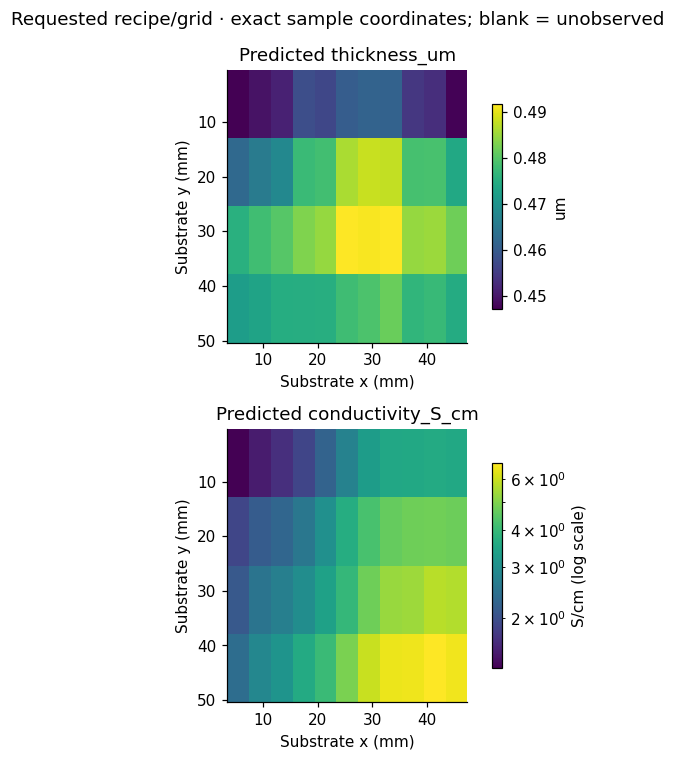

In [5]:
fitted = joblib.load(RESULTS / 'model.joblib')
def predict_substrate(recipe, grid, spacing_mm=None):
    return exp.predict_substrate(fitted, recipe, grid, spacing_mm)

reference_grid = full_map[['position', 'x_mm', 'y_mm', 'local_temperature_C']].copy()
reference_recipe = exp.example_recipe(ctx, MAP_LIBRARY_ID)
reference_map = predict_substrate(reference_recipe, reference_grid)
# Validate the unchanged reference BEFORE trying a modified recipe or grid.
np.testing.assert_allclose(reference_map[['predicted_thickness_um', 'predicted_conductivity_S_cm']],
                           full_map[['predicted_thickness_um', 'predicted_conductivity_S_cm']], rtol=5e-5, atol=1e-7)
recipe = dict(reference_recipe)
grid = reference_grid.copy()  # EDIT planned grid here, after the reference check.
# EDIT a planned temperature profile, for example: grid['local_temperature_C'] = 350
# Changing initial temperature alone does NOT redefine the specified local profile.
predicted_map = predict_substrate(recipe, grid)
display(pd.Series(recipe, name='RECIPE SETTINGS').to_frame())
display(predicted_map.head())
fig = htem.plot_substrate_maps(predicted_map)
fig.savefig(RESULTS / 'requested_recipe_maps.png', bbox_inches='tight')
plt.show()
predicted_map.to_csv(RESULTS / 'requested_recipe_map.csv', index=False)

Record your hypothesis, configuration, validation outcome, and next experiment. Run all five
architecture notebooks before `03_HTEM_Compare_Architectures.ipynb`. The comparison rejects stale
preparation, different labeled rows/targets, missing runs, and changed result files. Better scores
on one fixed holdout do not establish statistical superiority; do not repeatedly optimize on test.